# Clustering of the Data

In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture


DATA_PATH = Path(r"NREL_DEL.csv")

In [20]:
# Preview the data
df = pd.read_csv(DATA_PATH)
print(df.head())

         Hs        Tp    Vw_mean    Vw_std        RPM      Pitch  \
0  1.248500  4.757716   9.203143  1.749217   9.972552   0.019171   
1  1.574769  6.303943  11.370682  1.839102  11.694177   1.296207   
2  0.895745  5.364305  11.460520  1.651695  11.757063   1.184234   
3  0.638518  7.412787   6.598440  1.438964   8.256958   0.000000   
4  2.740453  5.828636  15.811478  2.406468  12.093967  10.479204   

            DEL  operating_state  
0  1.460472e+06                0  
1  1.733923e+06                0  
2  1.831648e+06                0  
3  8.610574e+05                0  
4  2.552811e+06                0  


In [21]:
# Load the data into variables
Hs = df["Hs"].values
Tp = df["Tp"].values
Vw_mean = df["Vw_mean"].values
Vw_std = df["Vw_std"].values
RPM = df["RPM"].values
Pitch = df["Pitch"].values
DEL = df["DEL"].values
operating_state = df["operating_state"].values

## Prepare the clustering features

K-means uses Euclidean distance, so the environmental variables are standardised first. The direction is converted to two periodic coordinates; the original direction is retained for reporting.

In [26]:
feature_columns = ["Hs", "Tp", "Vw_mean"]
feature_data = ["Hs", "Tp", "Vw_mean", "DEL"]

In [4]:
X = df[["Hs", "Tp", "Vw_mean"]].copy()
scaler = StandardScaler()
features = scaler.fit_transform(X)

## Method 1: K-Means 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


def cluster_operating_state(df, state, feature_columns=None, state_column="operating_state", random_state=100, max_k=12, show_plots=True,):
    """ Perform K-means clustering on a selected operating state. """


    feature_columns = ["Hs","Tp", "Vw_mean","Vw_std","RPM","Pitch"]

    # --------------------------------------------------
    # Filter chosen operating state
    # --------------------------------------------------
    df_state = (df.loc[df[state_column] == state].copy().reset_index(drop=True))
    df_state = df_state.dropna(subset=feature_columns)

    # --------------------------------------------------
    # Scale features
    # --------------------------------------------------
    scaler = StandardScaler()
    X = scaler.fit_transform(df_state[feature_columns])

    # --------------------------------------------------
    # Find optimal k
    # --------------------------------------------------
    candidate_k = range(2,min(max_k, len(df_state) - 1) + 1)

    silhouette_scores = []

    for k in candidate_k:
        model = KMeans(n_clusters=k,n_init=20,random_state=random_state )
        labels = model.fit_predict(X)
        score = silhouette_score(X, labels)
        silhouette_scores.append(score)

    selection = pd.DataFrame({"k": list(candidate_k),"silhouette": silhouette_scores,})
    selected_k = int(selection.loc[selection["silhouette"].idxmax(), "k" ])

    # --------------------------------------------------
    # Final K-means
    # --------------------------------------------------
    kmeans = KMeans(n_clusters=selected_k, n_init=50, random_state=random_state)
    df_state["cluster"] = kmeans.fit_predict(X)

    # --------------------------------------------------
    # Representative states
    # --------------------------------------------------

    centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=feature_columns,)
    probabilities = (df_state["cluster"].value_counts(normalize=True).sort_index())
    centers["occurrence_probability"] = (probabilities.values)
    centers["cluster"] = np.arange(selected_k)
    centers = (centers.sort_values("Vw_mean").reset_index(drop=True))

    # --------------------------------------------------
    # Plotting
    # --------------------------------------------------

    if show_plots:
        fig, axes = plt.subplots(1, 3, figsize=(16, 4))

        # Silhouette
        axes[0].plot(selection["k"],selection["silhouette"],marker="o")
        axes[0].axvline(selected_k,color="red",linestyle="--")
        axes[0].set(xlabel="Number of clusters (k)",ylabel="Silhouette score",title=f"State {state}: chosen k={selected_k}")

        # Cluster map
        axes[1].scatter(df_state["Vw_mean"],df_state["Hs"],c=df_state["cluster"],cmap="tab10",s=8,alpha=0.35)
        axes[1].scatter(centers["Vw_mean"],centers["Hs"],color="black",marker="x",s=80)

        axes[1].set(xlabel="Mean wind speed (m/s)",ylabel="Hs (m)", title="Representative states")

        # Occurrence
        axes[2].bar(np.arange(len(centers)), centers["occurrence_probability"])
        axes[2].set( xlabel="Representative state",ylabel="Occurrence probability", title="Cluster probability")

        plt.tight_layout()
        plt.show()

    return {
        "data": df_state,
        "centers": centers,
        "selection": selection,
        "selected_k": selected_k,
        "kmeans": kmeans,
        "scaler": scaler,
    }

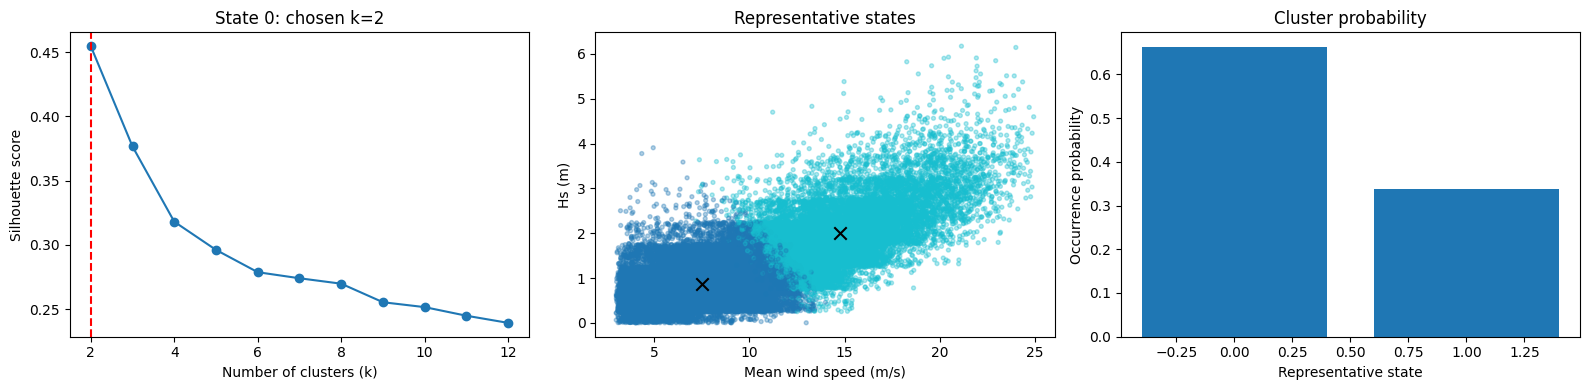

In [43]:
results_normal = cluster_operating_state(df, state=0)

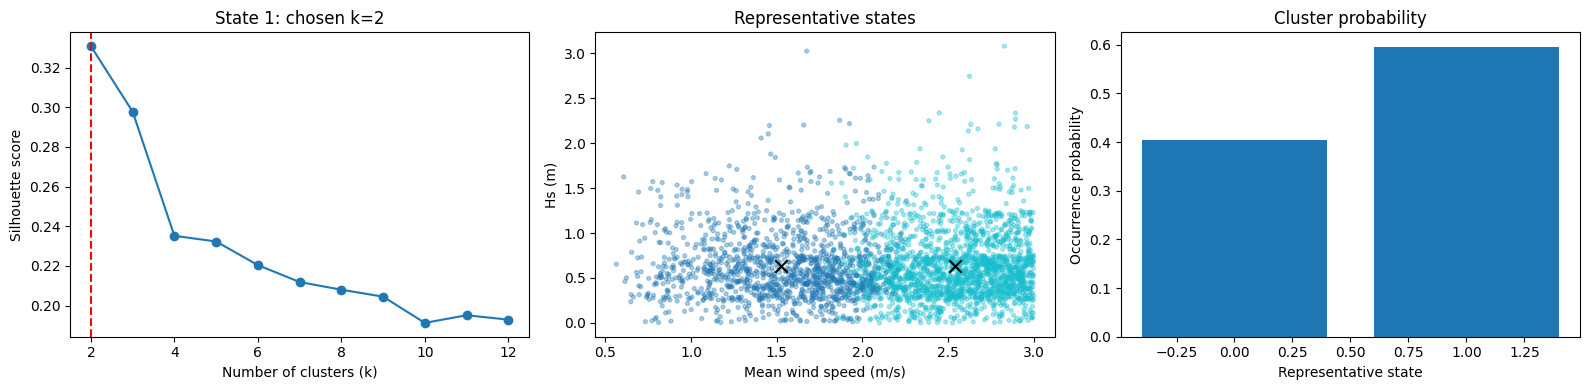

In [41]:
results_below_cutin = cluster_operating_state(df, state=1)

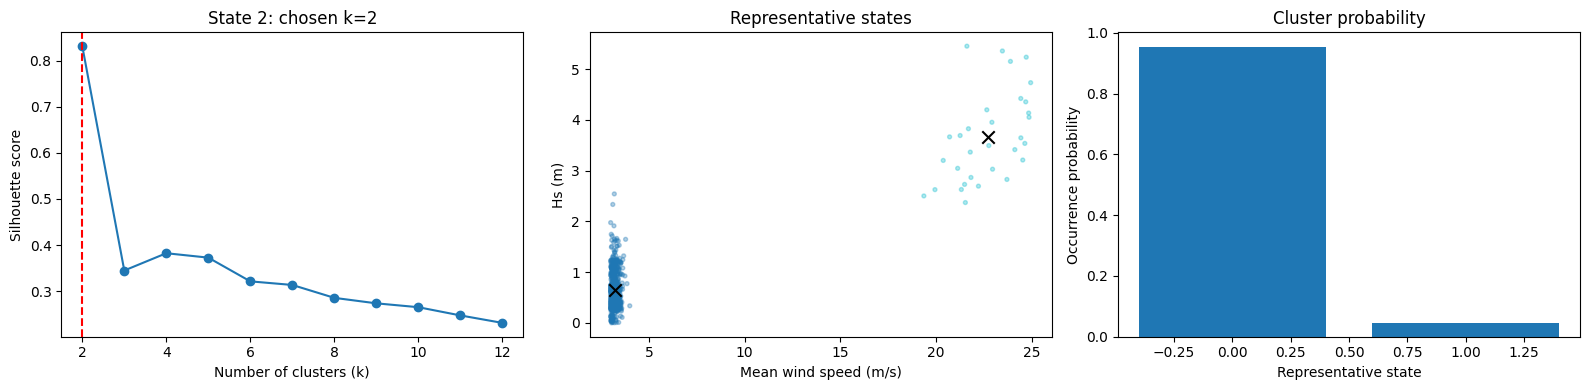

In [ ]:
results_startup = cluster_operating_state(df, state=2)

In [ ]:
results_startup = cluster_operating_state(df, state=3)

## Model 2: Gaussian Model Mixture (GMM)

In [5]:
def gmm_component_selection(X, max_components=12, random_state=100):
    """ Select the optimal number of components for a Gaussian Mixture Model using BIC. """

    k_range = range(1, 11)
    bic = [GaussianMixture(n_components=k, random_state=42).fit(X).bic(X) for k in k_range]

    plt.figure(figsize=(8, 4))
    plt.plot(k_range, bic, 'o-')
    plt.xlabel('Number of components k'); plt.ylabel('BIC (lower is better)')
    plt.title('GMM component selection'); plt.grid(alpha=0.3); plt.show()

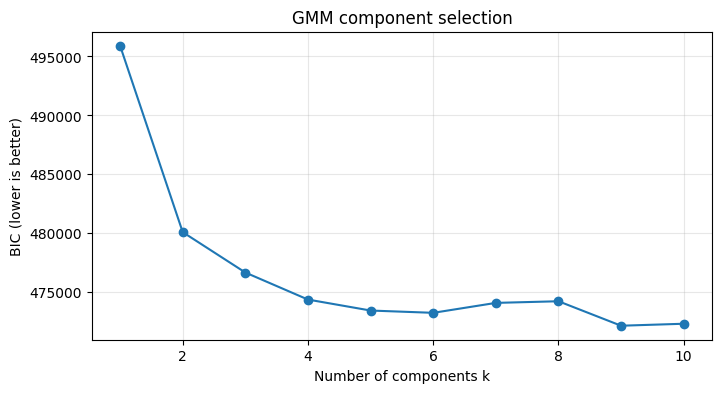

In [6]:
gmm_results_normal = gmm_component_selection(X, max_components=12, random_state=100)

In [ ]:
def cluster_operating_state_gmm(df, state, k_num, feature_columns, random_state=100, show_plots=True):

    # Keep only the requested operating state and usable feature rows
    df_state = df.loc[df["operating_state"] == state].copy()
    feature_data = ( df_state[feature_columns] .replace([np.inf, -np.inf], np.nan) .dropna() ) 
    df_state = df_state.loc[feature_data.index].copy()

    # Normalize the features
    scaler = StandardScaler()
    X = scaler.fit_transform(feature_data)

    # Run Gaussian Mixture Model clustering
    gmm = GaussianMixture(n_components=k_num, random_state=random_state)
    df_state["cluster"] = gmm.fit_predict(X)

    # Get cluster centers and occurrence probabilities
    centers = pd.DataFrame(scaler.inverse_transform(gmm.means_),columns=feature_columns,)
    centers.insert(0, "cluster", np.arange(k_num))
    probabilities = (df_state["cluster"].value_counts(normalize=True).reindex(range(k_num), fill_value=0))
    centers["occurrence_probability"] = probabilities.to_numpy()

    # Plot
    if show_plots:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        if "Vw_mean" in feature_columns and "Hs" in feature_columns:
            axes[0].scatter( df_state["Vw_mean"], df_state["Hs"], c=df_state["cluster"], s=8, alpha=0.35, cmap="tab10", ) 
            axes[0].scatter( centers["Vw_mean"], centers["Hs"], c="black", marker="x", s=70, label="GMM mean", ) 
            axes[0].set( xlabel="Mean wind speed (m/s)", ylabel="Significant wave height (m)", title=f"State {state}: {k_num} clusters")
            axes[0].legend()

        centers_sorted = centers.sort_values("Vw_mean")
        axes[1].bar(np.arange(len(centers_sorted)),centers_sorted["occurrence_probability"],)
        axes[1].set(xlabel="Representative state (sorted by wind speed)",ylabel="Occurrence probability",title="Cluster frequencies")

        plt.tight_layout()
        plt.show()

    return {
        "df_state": df_state,
        "centers": centers,
        "model": gmm,
        "scaler": scaler,
        "k_num": k_num,
    }

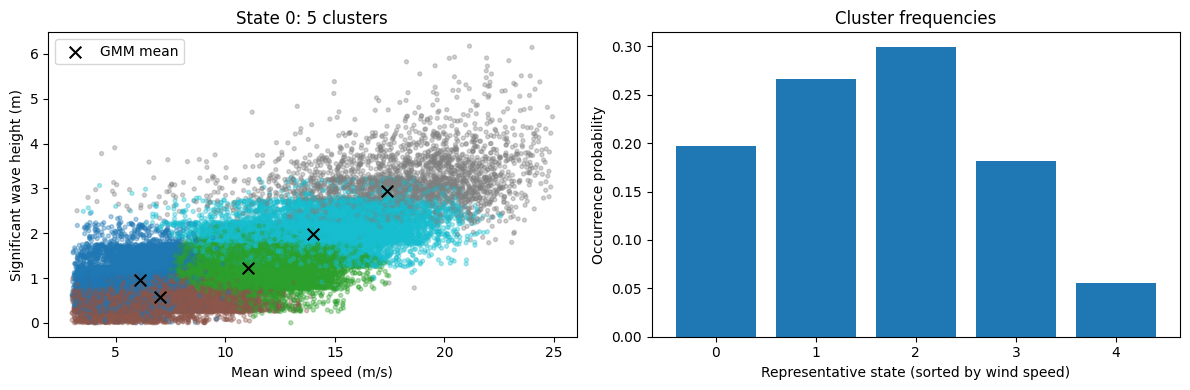

   cluster        Hs        Tp    Vw_mean  occurrence_probability
0        0  0.951278  6.448979   6.122505                0.197200
1        1  1.224736  5.768494  11.049101                0.299502
2        2  0.573685  4.860673   7.010156                0.266544
3        3  2.949497  8.154653  17.375572                0.055454
4        4  1.981919  6.877621  13.987766                0.181300


In [34]:
# Change this based on the plot!
GMM_NORM_K = 5

# Make the analysis for the normal operating state
gmm_results_normal = cluster_operating_state_gmm(df, state=0, k_num=GMM_NORM_K, feature_columns=feature_columns)
print(gmm_results_normal["centers"])

In [31]:
cluster_summary = (
    df.groupby(gmm_results_normal["df_state"]["cluster"])
      .agg({
          "Hs": "mean",
          "Tp": "mean",
          "Vw_mean": "mean",
          "DEL": "mean"
      })
)
print(cluster_summary)

               Hs        Tp    Vw_mean           DEL
cluster                                             
0.0      1.020150  6.212148   6.710162  9.736876e+05
1.0      1.767354  6.489110  14.144346  2.255410e+06
2.0      1.223424  5.838792  10.370593  1.570713e+06
3.0      0.514651  5.230558   5.471100  7.531030e+05
4.0      2.628542  7.477961  18.010341  2.181143e+06


In [33]:
# Lumping error 

from sklearn.metrics import mean_squared_error, r2_score


true_damage = df["DEL"].sum()
df["DEL_lumped"] = (df.groupby(gmm_results_normal["df_state"]["cluster"])["DEL"].transform("mean"))

rmse = np.sqrt(
    mean_squared_error(
        df["DEL"],
        df["DEL_lumped"]
    )
)

r2_score(
    df["DEL"],
    df["DEL_lumped"]
)

ValueError: Input contains NaN.